<a href="https://colab.research.google.com/github/likithdr06/DLNN-lab-exp/blob/main/Exp_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Bidirectional, Dense, Input

np.random.seed(42)
tf.random.set_seed(42)

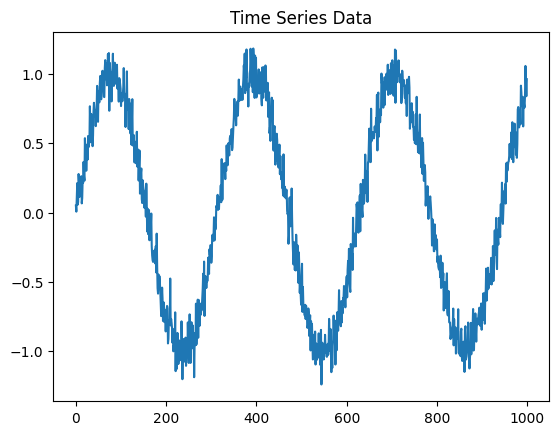

In [ ]:
time = np.arange(1000)

data = np.sin(time * 0.02) + np.random.normal(0, 0.1, 1000)

df = pd.DataFrame({'Value': data})

plt.plot(df['Value'])
plt.title("Time Series Data")
plt.show()

In [ ]:
scaler = MinMaxScaler()

scaled_data = scaler.fit_transform(df[['Value']])

print("Data Normalized Successfully")

Data Normalized Successfully


In [ ]:
def create_sequences(data, window=20):

    X, y = [], []

    for i in range(len(data) - window):
        X.append(data[i:i+window])
        y.append(data[i+window])

    return np.array(X), np.array(y)

X, y = create_sequences(scaled_data)

print("Input Shape:", X.shape)
print("Output Shape:", y.shape)

Input Shape: (980, 20, 1)
Output Shape: (980, 1)


In [ ]:
split = int(len(X) * 0.8)

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (784, 20, 1)
Testing: (196, 20, 1)


In [ ]:
lstm_model = Sequential([
    Input(shape=(20, 1)),
    LSTM(64),
    Dense(32, activation='relu'),
    Dense(1)
])

lstm_model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,009 (74.25 KB)

 Trainable params: 19,009 (74.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
lstm_model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=32,
    validation_split=0.2
)

print("LSTM Training Completed")

Epoch 1/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 30ms/step - loss: 0.0523 - mae: 0.1595 - val_loss: 0.0070 - val_mae: 0.0695
Epoch 2/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0060 - mae: 0.0638 - val_loss: 0.0047 - val_mae: 0.0562
Epoch 3/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0040 - mae: 0.0513 - val_loss: 0.0041 - val_mae: 0.0526
Epoch 4/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0034 - mae: 0.0473 - val_loss: 0.0043 - val_mae: 0.0539
Epoch 5/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0032 - mae: 0.0459 - val_loss: 0.0043 - val_mae: 0.0545
Epoch 6/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0031 - mae: 0.0450 - val_loss: 0.0041 - val_mae: 0.0529
Epoch 7/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0030 - mae: 0.0443 - val_loss: 0.0038 - val_mae: 0.0505
Epoch 8/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0029 - mae: 0.0435 - val_loss: 0.0035 - val_mae: 0.0481
Epoch 9/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.002

In [ ]:
lstm_model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=32,
    validation_split=0.2
)

print("LSTM Training Completed")

Epoch 1/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0025 - mae: 0.0398 - val_loss: 0.0024 - val_mae: 0.0382
Epoch 2/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0024 - mae: 0.0395 - val_loss: 0.0024 - val_mae: 0.0374
Epoch 3/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0024 - mae: 0.0392 - val_loss: 0.0023 - val_mae: 0.0368
Epoch 4/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0024 - mae: 0.0390 - val_loss: 0.0023 - val_mae: 0.0364
Epoch 5/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0024 - mae: 0.0390 - val_loss: 0.0022 - val_mae: 0.0361
Epoch 6/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0024 - mae: 0.0390 - val_loss: 0.0022 - val_mae: 0.0360
Epoch 7/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0024 - mae: 0.0391 - val_loss: 0.0022 - val_mae: 0.0359
Epoch 8/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0024 - mae: 0.0391 - val_loss: 0.0022 - val_mae: 0.0358
Epoch 9/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.002

In [ ]:
bi_model = Sequential([
    Input(shape=(20, 1)),
    Bidirectional(LSTM(64)),
    Dense(32, activation='relu'),
    Dense(1)
])

bi_model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

bi_model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=32,
    validation_split=0.2
)

print("BiLSTM Training Completed")

Epoch 1/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - loss: 0.0855 - mae: 0.1977 - val_loss: 0.0183 - val_mae: 0.1160
Epoch 2/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0083 - mae: 0.0753 - val_loss: 0.0057 - val_mae: 0.0643
Epoch 3/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0052 - mae: 0.0610 - val_loss: 0.0059 - val_mae: 0.0644
Epoch 4/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 0.0049 - mae: 0.0580 - val_loss: 0.0050 - val_mae: 0.0590
Epoch 5/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - loss: 0.0045 - mae: 0.0554 - val_loss: 0.0042 - val_mae: 0.0534
Epoch 6/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - loss: 0.0039 - mae: 0.0517 - val_loss: 0.0037 - val_mae: 0.0496
Epoch 7/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - loss: 0.0037 - mae: 0.0496 - val_loss: 0.0034 - val_mae: 0.0479
Epoch 8/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0035 - mae: 0.0481 - val_loss: 0.0035 - val_mae: 0.0480
Epoch 9/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.003

In [ ]:
print("LSTM Results:")
print(lstm_model.evaluate(X_test, y_test))

print("\nBidirectional LSTM Results:")
print(bi_model.evaluate(X_test, y_test))

LSTM Results:
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0020 - mae: 0.0354 
[0.0019551487639546394, 0.03543907776474953]

Bidirectional LSTM Results:
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0020 - mae: 0.0357 
[0.0019680485129356384, 0.035733990371227264]


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step


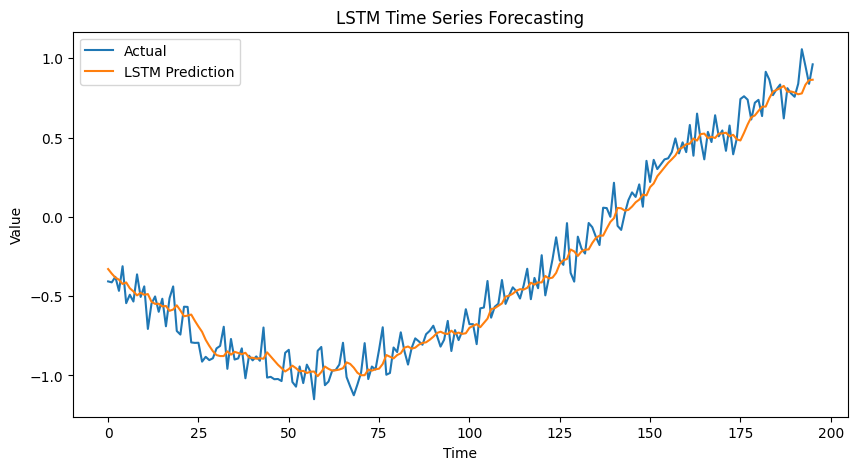

In [ ]:
pred = lstm_model.predict(X_test)

pred = scaler.inverse_transform(pred)
actual = scaler.inverse_transform(y_test)

plt.figure(figsize=(10,5))

plt.plot(actual, label="Actual")
plt.plot(pred, label="LSTM Prediction")

plt.title("LSTM Time Series Forecasting")
plt.xlabel("Time")
plt.ylabel("Value")

plt.legend()
plt.show()